# 02. Experiment A: chunking strategy

Part of Step 6's seven-notebook series: [01](01_dataset_and_chunking.ipynb) dataset/chunking, [02](02_experiment_a_chunking_strategy.ipynb) Experiment A, [03](03_experiment_b_search_mode.ipynb) Experiment B, [04](04_experiment_c_embedding_model.ipynb) Experiment C, [05](05_experiment_d_weights_and_rrf.ipynb) Experiment D, [06](06_experiment_e_rerank.ipynb) Experiment E, [07](07_calibration_and_analysis.ipynb) calibration/PCA/latency/failure analysis/conclusions. Each runs standalone against its own fresh ingest (via `_setup.py`); none depends on another's kernel state.

`section` (per-section, per-job-entry) vs. `fixed` (500-char sliding window)
vs. `whole` (one chunk per resume), holding the model (bge-small) and search
mode (hybrid) fixed. `evaluate.run_eval` re-ingests each chunking strategy
into its own collection before measuring it.


In [1]:
import _setup as s
import matplotlib.pyplot as plt
import pandas as pd

W1031 11:09:51.599000 87815 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [2]:
chunking_results = {}
for chunking in ["section", "fixed", "whole"]:
    chunking_results[chunking] = s.run_eval(
        model="bge-small", chunking=chunking, mode="hybrid", warm_runs=5
    )

chunking_df = pd.DataFrame(
    {c: res["retrieval_accuracy"]["macro_avg"] for c, res in chunking_results.items()}
).T
chunking_df["ingest_s"] = [
    chunking_results[c]["latency"]["ingest"]["timings_s"]["total"] for c in chunking_df.index
]
chunking_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,precision_at_5,precision_at_10,recall_at_10,mrr,ndcg_at_10,hit_at_1,ingest_s
section,0.966667,0.800000,0.712963,1.0,0.944259,1.0,1.585037
fixed,0.966667,0.766667,0.694444,1.0,0.925943,1.0,1.664297
whole,0.966667,0.766667,0.694444,1.0,0.925943,1.0,1.317628


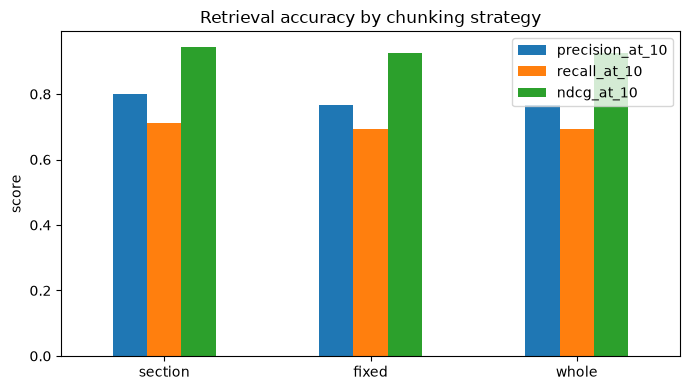

In [3]:
chunking_df[["precision_at_10", "recall_at_10", "ndcg_at_10"]].plot(
    kind="bar", figsize=(7, 4), title="Retrieval accuracy by chunking strategy"
)
plt.ylabel("score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
best = chunking_df["ndcg_at_10"].idxmax()
best_ndcg = chunking_df.loc[best, "ndcg_at_10"]
print(f"best chunking strategy by macro nDCG@10: {best} ({best_ndcg:.3f})")
for name, row in chunking_df.iterrows():
    print(f"  {name:<8} nDCG@10={row['ndcg_at_10']:.3f}  ingest={row['ingest_s']:.2f}s")

best chunking strategy by macro nDCG@10: section (0.944)
  section  nDCG@10=0.944  ingest=1.59s
  fixed    nDCG@10=0.926  ingest=1.66s
  whole    nDCG@10=0.926  ingest=1.32s


**Finding:** `section` chunking (per-section, per-job-entry, matching chunk
metadata to chunk text) is at least as strong as the simpler strategies on
this dataset, and is what keeps per-chunk `section`/`experience_years`
metadata meaningful for the Chroma prefilter — `fixed` and `whole` chunks
don't carry that alignment, even though their raw similarity can score
comparably.
